In [2]:
import os
from pathlib import Path

from dotenv import load_dotenv
import mlflow
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import normalize
import umap

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Locate the repo from the current directory, so the notebook runs from anywhere.
HERE = Path.cwd()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError(
        f"Start the notebook inside the repo: no pyproject.toml above {HERE}."
    )
DATA_DIR = ROOT / "data"

In [4]:
load_dotenv(ROOT / ".env")  # shell env wins; .env is optional

MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://127.0.0.1:5000")
MLFLOW_EXPERIMENT = os.getenv("MLFLOW_VALID_EXPERIMENT", "CAH-clustering")

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT)

2026/11/05 22:51:17 INFO mlflow.tracking.fluent: Experiment with name 'CAH-clustering' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1793919077215, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1793919077215, lifecycle_stage='active', name='CAH-clustering', tags={}, trace_location=None, workspace='default'>

In [5]:
sns.set_style("white")
TAB10_PALETTE = sns.color_palette("tab10")

In [6]:
df = pd.read_csv(DATA_DIR / "arxiv_papers_preprocessed.csv")
X_v1 = np.load(DATA_DIR / "arxiv_embeddings_v1.npy")
X_v2 = np.load(DATA_DIR / "arxiv_embeddings_v2.npy")

In [7]:
CAH_PARAMS = {"method": "ward", "metric": "euclidean"}

In [8]:
def build_linkage(X, **params):
    return linkage(X, **{**CAH_PARAMS, **params})


def cut_tree(Z, k):
    return fcluster(Z, t=k, criterion="maxclust") - 1


def within_ss(X, labels):
    return sum(
        ((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum()
        for c in np.unique(labels)
    )


def sweep_k(X, k_range, **params):
    ks = list(k_range)
    Z = build_linkage(X, **params)
    inertia_list, silhouette_list, labels_by_k = [], [], {}
    for k in ks:
        labels = cut_tree(Z, k)
        labels_by_k[k] = labels
        inertia_list.append(within_ss(X, labels))
        silhouette_list.append(silhouette_score(X, labels))
    return ks, inertia_list, silhouette_list, Z, labels_by_k


def plot_k_sweep(ks, inertia_list, silhouette_list, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    ax1.plot(ks, inertia_list, marker="o", markersize=4, linewidth=1.5,
             alpha=0.7, color=TAB10_PALETTE[0])
    ax2.plot(ks, silhouette_list, marker="o", markersize=4, linewidth=1.5,
             alpha=0.7, color=TAB10_PALETTE[1])

    ax1.set(xlabel="k (number of clusters)", ylabel="Within-cluster sum of squares")
    ax2.set(xlabel="k (number of clusters)", ylabel="Silhouette score")
    ax1.set_title("Elbow method", loc="left", fontsize=11)
    ax2.set_title("Silhouette", loc="left", fontsize=11)
    for ax in (ax1, ax2):
        ax.set_xticks(ks)
        sns.despine(ax=ax)

    fig.suptitle(f"CAH model selection: {title}", x=0.01, ha="left", fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.92))
    return fig


def plot_dendrogram(Z, k, title, p=30):
    fig, ax = plt.subplots(figsize=(12, 5))
    dendrogram(Z, truncate_mode="lastp", p=p,
               no_labels=True, ax=ax)
    ax.set_ylabel("Merge distance")
    ax.set_title(f"Dendrogram (last {p} merges), cut at k={k}: {title}",
                 loc="left", fontsize=11)
    sns.despine(ax=ax)
    plt.tight_layout()
    return fig


def log_sweep(run_name, ks, inertia_list, silhouette_list, metadata, params, fig1, fig2):
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({"k_min": ks[0], "k_max": ks[-1], **params, **metadata})
        for k, inertia, sil in zip(ks, inertia_list, silhouette_list):
            with mlflow.start_run(run_name=f"k={k}", nested=True):
                mlflow.log_param("n_clusters", k)
                mlflow.log_metric("within_ss", inertia)
                mlflow.log_metric("silhouette", sil)
        mlflow.log_figure(fig1, "elbow_silhouette.png")
        mlflow.log_figure(fig2, "dendrogram.png")


def run(X, run_name, metadata, k_range=range(2, 11), **model_params):
    """Run one CAH sweep. `metadata` is logged only; `model_params` configure linkage."""
    params = {**CAH_PARAMS, **model_params}
    ks, inertia_list, silhouette_list, Z, labels_by_k = sweep_k(X, k_range, **model_params)
    subtitle = ", ".join(f"{key}={value}" for key, value in params.items())
    fig1 = plot_k_sweep(ks, inertia_list, silhouette_list, f"{run_name}\n{subtitle}")
    fig2 = plot_dendrogram(Z, k=9, title="CAH_L2Norm_UMAP10")
    log_sweep(run_name, ks, inertia_list, silhouette_list, metadata, params, fig1, fig2)
    plt.show()
    return ks, inertia_list, silhouette_list, Z, labels_by_k

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


🏃 View run k=2 at: http://127.0.0.1:5000/#/experiments/2/runs/1c53abd6b0e8451b9a5f4db4d1f02539
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=3 at: http://127.0.0.1:5000/#/experiments/2/runs/3abf5aac73134ba88d82fd713b5a284f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=4 at: http://127.0.0.1:5000/#/experiments/2/runs/4f02cdf1caad43619df2b127a4cba27e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=5 at: http://127.0.0.1:5000/#/experiments/2/runs/a85cf4b5d39745cbb5477980fb6c9cee
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=6 at: http://127.0.0.1:5000/#/experiments/2/runs/88c95e348fc849c2b9f4849ec1c810b9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=7 at: http://127.0.0.1:5000/#/experiments/2/runs/f4a763ec45794b7d903018130283e00a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=8 at: http://127.0.0.1:5000/#/experiments/2/runs/76c28947

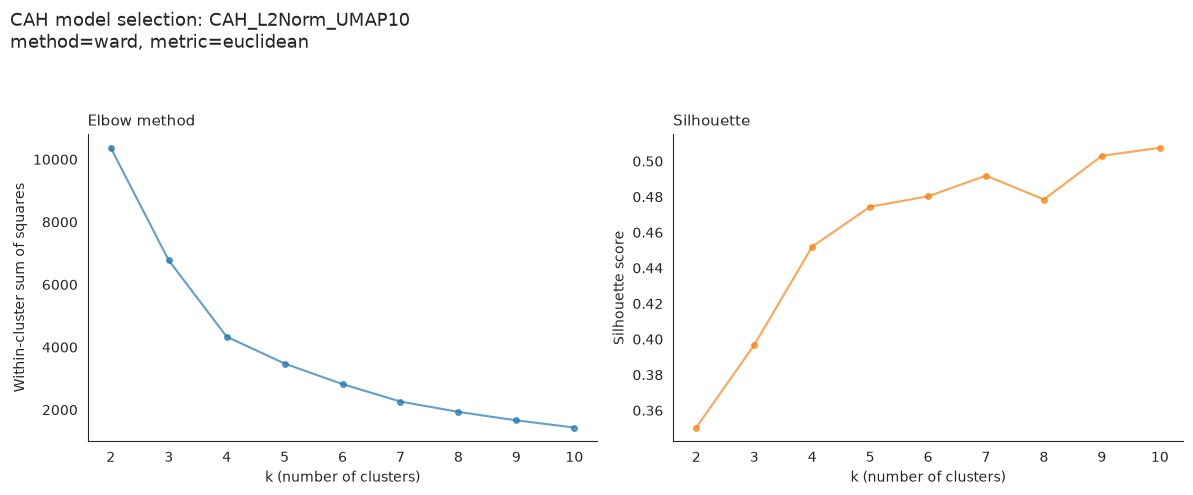

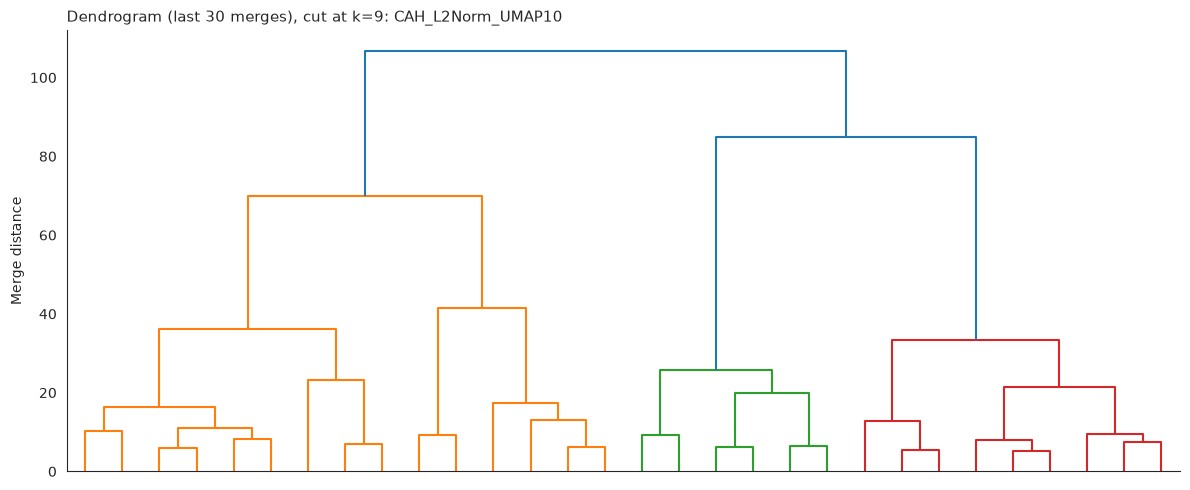

In [9]:
X_norm_v1 = normalize(X_v1)
reducer = umap.UMAP(
    n_components=10, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=42
)
X_umap_v1 = reducer.fit_transform(X_norm_v1)

ks, inertia_list, silhouette_list, Z, labels_by_k = run(
    X_umap_v1,
    "CAH_L2Norm_UMAP10",
    metadata={"preprocessing": "L2norm", "reduction": "UMAP", "umap_n_components": 10},
)

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


🏃 View run k=2 at: http://127.0.0.1:5000/#/experiments/2/runs/cb6c9335ccdd4bfabc8afedcad735437
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=3 at: http://127.0.0.1:5000/#/experiments/2/runs/9a0b05a15ee946d09cf4891b0b266530
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=4 at: http://127.0.0.1:5000/#/experiments/2/runs/508f468ce59c450f974cce9b3e619740
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=5 at: http://127.0.0.1:5000/#/experiments/2/runs/57fdac96a37a4f2bbca4d8b2f2e455dc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=6 at: http://127.0.0.1:5000/#/experiments/2/runs/cd1de6497cfd40f1aa2bd2219fe6a79c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=7 at: http://127.0.0.1:5000/#/experiments/2/runs/a06bcbcda90d4739a3d260e97e3d3267
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run k=8 at: http://127.0.0.1:5000/#/experiments/2/runs/70d4700f

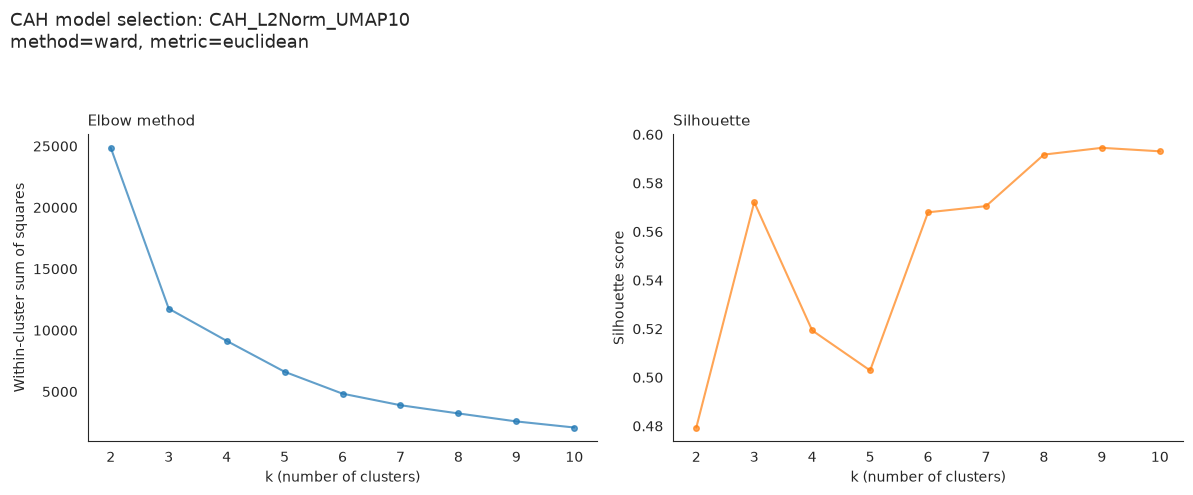

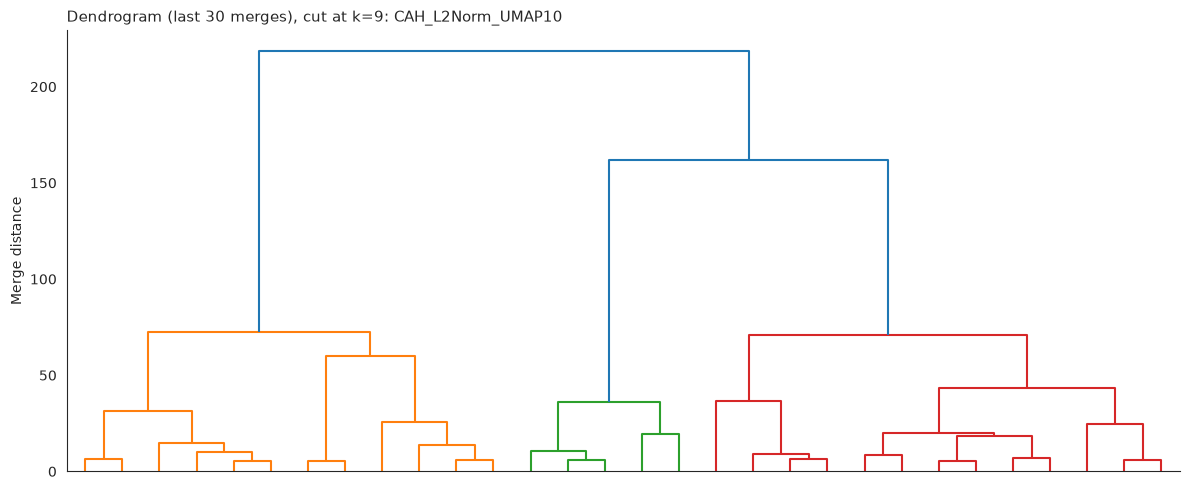

In [10]:
X_norm_v2 = normalize(X_v2)
reducer = umap.UMAP(
    n_components=10, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=42
)
X_umap_v2 = reducer.fit_transform(X_norm_v2)

ks, inertia_list, silhouette_list, Z, labels_by_k = run(
    X_umap_v2,
    "CAH_L2Norm_UMAP10",
    metadata={"preprocessing": "L2norm", "reduction": "UMAP", "umap_n_components": 10},
)

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


🏃 View run cah_clusters_umap2d_k6_k9 at: http://127.0.0.1:5000/#/experiments/2/runs/cccde8cf21b143c8900a16b8d7507533
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


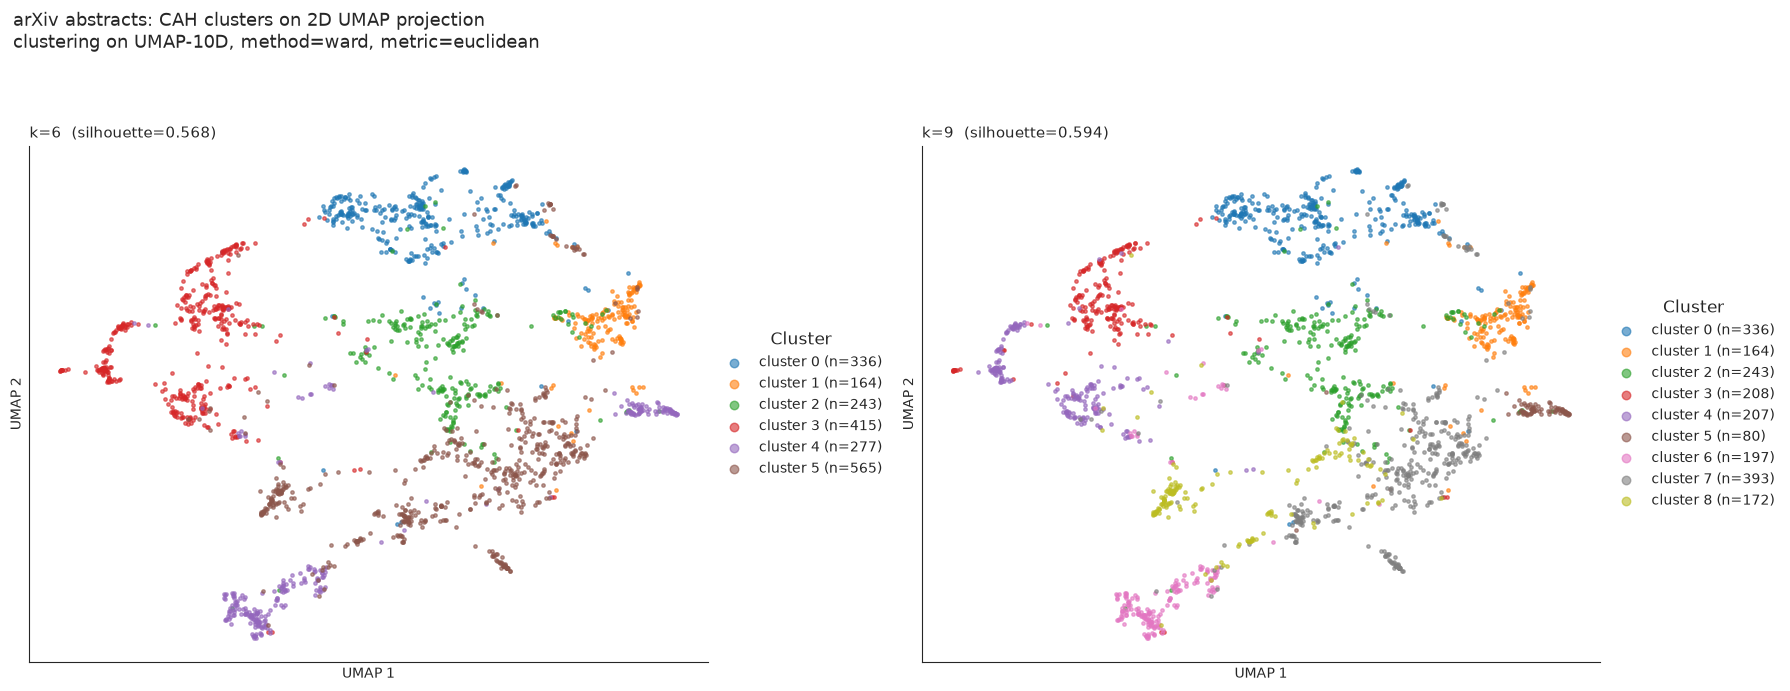

In [11]:
reducer_2d = umap.UMAP(
    n_components=2, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=42
)
X_2d_v1 = reducer_2d.fit_transform(X_norm_v1)

candidate_ks = [6, 9]
# labels_by_k and silhouette_list come from run(...) of the CAH sweep
sil_by_k = dict(zip(ks, silhouette_list))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, k in zip(axes, candidate_ks):
    labels = labels_by_k[k]
    colors = TAB10_PALETTE[:k]
    sil = sil_by_k[k]

    for c in range(k):
        mask = labels == c
        ax.scatter(
            X_2d_v1[mask, 0],
            X_2d_v1[mask, 1],
            s=6,
            alpha=0.6,
            color=colors[c],
            label=f"cluster {c} (n={mask.sum()})",
        )

    ax.set_title(f"k={k}  (silhouette={sil:.3f})", loc="left", fontsize=11)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_xticks([])
    ax.set_yticks([])
    sns.despine(ax=ax)
    ax.legend(
        title="Cluster",
        frameon=False,
        loc="center left",
        bbox_to_anchor=(1.0, 0.5),
        markerscale=2.5,
        fontsize=10,
        title_fontsize=12,
    )

fig.suptitle(
    "arXiv abstracts: CAH clusters on 2D UMAP projection\n"
    "clustering on UMAP-10D, method=ward, metric=euclidean",
    x=0.01,
    ha="left",
    fontsize=13,
)
plt.tight_layout(rect=(0, 0, 1, 0.92))

with mlflow.start_run(run_name="cah_clusters_umap2d_k6_k9"):
    mlflow.log_params(
        {
            "candidate_ks": str(candidate_ks),
            "clustering_space": "UMAP10",
            "viz_space": "UMAP2",
            "linkage_method": "ward",
            "linkage_metric": "euclidean",
            "umap_n_neighbors": 15,
            "umap_min_dist": 0.0,
            "umap_metric": "cosine",
        }
    )
    mlflow.log_figure(fig, "cah_umap2d_k6_k9.png")

plt.show()

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


🏃 View run cah_clusters_umap2d_k6_k9 at: http://127.0.0.1:5000/#/experiments/2/runs/6f0f9b2ca09548a0b123ab76251aaafa
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


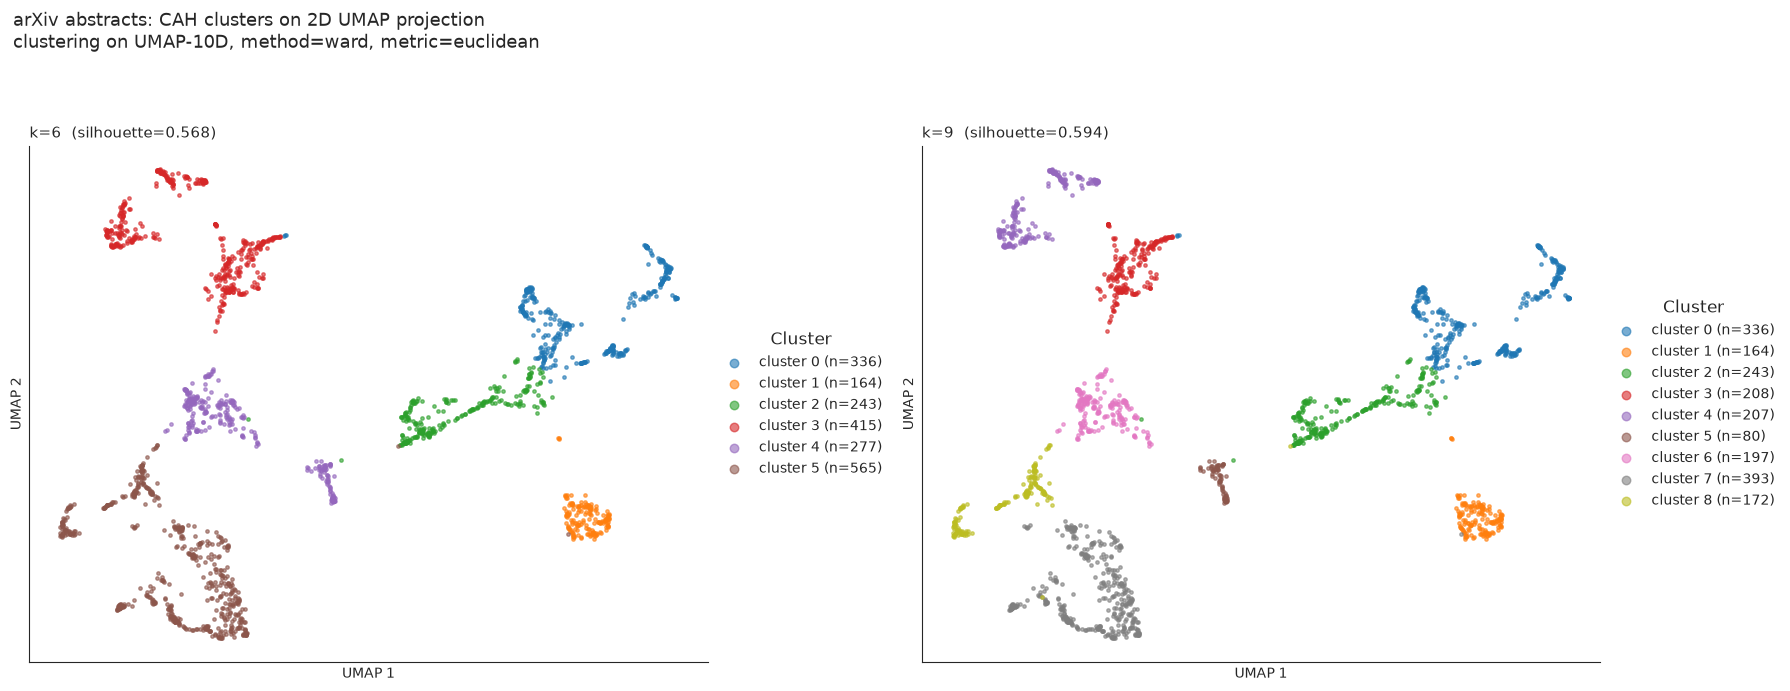

In [12]:
reducer_2d = umap.UMAP(
    n_components=2, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=42
)
X_2d_v2 = reducer_2d.fit_transform(X_norm_v2)

candidate_ks = [6, 9]
# labels_by_k and silhouette_list come from run(...) of the CAH sweep
sil_by_k = dict(zip(ks, silhouette_list))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, k in zip(axes, candidate_ks):
    labels = labels_by_k[k]
    colors = TAB10_PALETTE[:k]
    sil = sil_by_k[k]

    for c in range(k):
        mask = labels == c
        ax.scatter(
            X_2d_v2[mask, 0],
            X_2d_v2[mask, 1],
            s=6,
            alpha=0.6,
            color=colors[c],
            label=f"cluster {c} (n={mask.sum()})",
        )

    ax.set_title(f"k={k}  (silhouette={sil:.3f})", loc="left", fontsize=11)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_xticks([])
    ax.set_yticks([])
    sns.despine(ax=ax)
    ax.legend(
        title="Cluster",
        frameon=False,
        loc="center left",
        bbox_to_anchor=(1.0, 0.5),
        markerscale=2.5,
        fontsize=10,
        title_fontsize=12,
    )

fig.suptitle(
    "arXiv abstracts: CAH clusters on 2D UMAP projection\n"
    "clustering on UMAP-10D, method=ward, metric=euclidean",
    x=0.01,
    ha="left",
    fontsize=13,
)
plt.tight_layout(rect=(0, 0, 1, 0.92))

with mlflow.start_run(run_name="cah_clusters_umap2d_k6_k9"):
    mlflow.log_params(
        {
            "candidate_ks": str(candidate_ks),
            "clustering_space": "UMAP10",
            "viz_space": "UMAP2",
            "linkage_method": "ward",
            "linkage_metric": "euclidean",
            "umap_n_neighbors": 15,
            "umap_min_dist": 0.0,
            "umap_metric": "cosine",
        }
    )
    mlflow.log_figure(fig, "cah_umap2d_k6_k9.png")

plt.show()